
TRAINING DEEP ENSEMBLE

Training Finished.

UNCERTAINTY RESULTS @ 70°C

Rm
Mean = 9.691104e-01
Epistemic σ = 2.920590e-03
Aleatoric σ = 2.110350e-03
Combined σ = 3.603251e-03

Lm
Mean = 6.958068e-08
Epistemic σ = 1.819914e-10
Aleatoric σ = 1.166427e-10
Combined σ = 2.161629e-10

Cm
Mean = 6.014214e-14
Epistemic σ = 6.930884e-17
Aleatoric σ = 1.243317e-16
Combined σ = 1.423449e-16

Rs
Mean = 9.987682e-13
Epistemic σ = 7.675396e-17
Aleatoric σ = 1.863655e-15
Combined σ = 1.865235e-15

RESONANCE UNCERTAINTY
fr Mean = 2460.2557 MHz
fr Std  = 732.5148 kHz
fa Mean = 2551.6550 MHz
fa Std  = 740.8529 kHz


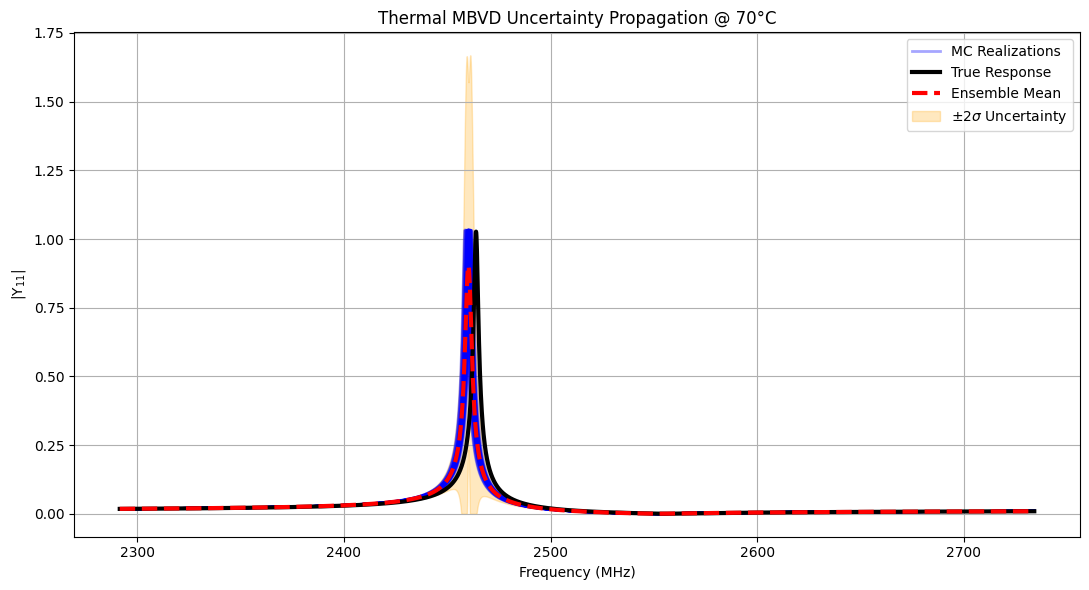


ALL EXPERIMENTS COMPLETED SUCCESSFULLY.


In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import random
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ================================================================
# GLOBAL REPRODUCIBILITY
# ================================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass

tf.get_logger().setLevel("ERROR")

# ================================================================
# CONSTANTS
# ================================================================

PI = math.pi

# ================================================================
# FIXED MBVD PARAMETERS
# ================================================================

C0 = 7.95e-13

R0 = 0.25

# ================================================================
# REFERENCE PARAMETERS
# ================================================================

fr0 = 2.468e9

Qs0 = 887

Qp0 = 3770

k20 = 0.08

# ================================================================
# TEMPERATURE COEFFICIENTS
# ================================================================

TCF1 = -35e-6
TCF2 = -4e-8
TCF3 = 2e-10

alpha1 = 5e-4
alpha2 = 2e-5

beta1 = 0.02
beta2 = 1e-4

gamma1 = 0.015
gamma2 = 8e-5

# ================================================================
# TRAINING SETTINGS
# ================================================================

N_ENSEMBLE = 5

EPOCHS = 1000

BATCH_SIZE = 16

# ================================================================
# TRUE THERMAL MBVD MODEL
# ================================================================

def true_ECPs(T):

    dT = T - 25.0

    # ------------------------------------------------------------
    # fr(T)
    # ------------------------------------------------------------

    fr = fr0 * (
        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3
    )

    # ------------------------------------------------------------
    # k2(T)
    # ------------------------------------------------------------

    k2 = k20 * (
        1
        + alpha1*dT
        + alpha2*dT**2
    )

    # ------------------------------------------------------------
    # Qs(T)
    # ------------------------------------------------------------

    Qs = Qs0 * np.exp(
        -beta1*dT/100
        + beta2*dT**2/10000
    )

    # ------------------------------------------------------------
    # Qp(T)
    # ------------------------------------------------------------

    Qp = Qp0 * np.exp(
        -gamma1*dT/100
        + gamma2*dT**2/10000
    )

    # ------------------------------------------------------------
    # fa(T)
    # ------------------------------------------------------------

    fa = (
        2*fr
        /
        (
            1
            +
            np.sqrt(
                1 - (16*k2)/(PI**2)
            )
        )
    )

    # ------------------------------------------------------------
    # ANGULAR FREQUENCIES
    # ------------------------------------------------------------

    wr = 2*np.pi*fr

    wa = 2*np.pi*fa

    # ------------------------------------------------------------
    # MBVD PARAMETERS
    # ------------------------------------------------------------

    Cm = C0 * (
        (fa/fr)**2 - 1
    )

    Lm = 1 / (
        (2*np.pi*fr)**2 * Cm
    )

    # ------------------------------------------------------------
    # CORRECTED Rm
    # ------------------------------------------------------------

    Rm = (

        wr * (Lm/Qs)

    ) - R0

    # ------------------------------------------------------------
    # Rs(T)
    # ------------------------------------------------------------

    Rs = (

        wa * (Lm/Qp)

    ) - Rm

    # ------------------------------------------------------------
    # SAFETY
    # ------------------------------------------------------------

    Rm = np.maximum(Rm,1e-12)

    Lm = np.maximum(Lm,1e-18)

    Cm = np.maximum(Cm,1e-18)

    Rs = np.maximum(Rs,1e-12)

    return np.array([
        Rm,
        Lm,
        Cm,
        Rs
    ])

# ================================================================
# STOCHASTIC NOISE
# ================================================================

def noisy_ECPs(T):

    values = true_ECPs(T).copy()

    noise = np.random.uniform(0.001,0.003)

    for i in range(len(values)):

        values[i] *= (
            1 + noise*np.random.randn()
        )

    return values

# ================================================================
# MBVD RESPONSE
# ================================================================

def simulate_Y11(Rm,Lm,Cm,Rs,T):

    dT = T - 25.0

    # ------------------------------------------------------------
    # fr(T)
    # ------------------------------------------------------------

    fr = fr0 * (
        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3
    )

    # ------------------------------------------------------------
    # k2(T)
    # ------------------------------------------------------------

    k2 = k20 * (
        1
        + alpha1*dT
        + alpha2*dT**2
    )

    # ------------------------------------------------------------
    # fa(T)
    # ------------------------------------------------------------

    fa = (
        2*fr
        /
        (
            1
            +
            np.sqrt(
                1 - (16*k2)/(PI**2)
            )
        )
    )

    # ------------------------------------------------------------
    # FREQUENCY GRID
    # ------------------------------------------------------------

    f = np.linspace(
        fr*0.93,
        fa*1.07,
        4000
    )

    w = 2*np.pi*f

    # ------------------------------------------------------------
    # STATIC BRANCH
    # ------------------------------------------------------------

    Zs = (
        R0
        +
        1/(1j*w*C0)
    )

    # ------------------------------------------------------------
    # MOTIONAL BRANCH
    # ------------------------------------------------------------

    Zm = (
        Rm
        +
        1j*w*Lm
        +
        1/(1j*w*Cm)
    )

    # ------------------------------------------------------------
    # PARALLEL COMBINATION
    # ------------------------------------------------------------

    Zp = 1/(1/Zs + 1/Zm)

    # ------------------------------------------------------------
    # TOTAL IMPEDANCE
    # ------------------------------------------------------------

    Ztotal = Rs + Zp

    # ------------------------------------------------------------
    # ADMITTANCE
    # ------------------------------------------------------------

    Y11 = np.abs(
        1/Ztotal
    )

    return f,Y11

# ================================================================
# BUILD MODEL
# ================================================================

def build_model():

    tf.keras.backend.clear_session()

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(1,)),

        tf.keras.layers.Dense(
            64,
            activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(1e-4)
        ),

        tf.keras.layers.Dense(
            64,
            activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(1e-4)
        ),

        tf.keras.layers.Dense(
            32,
            activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(1e-4)
        ),

        tf.keras.layers.Dense(4)

    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="mse"
    )

    return model

# ================================================================
# TRAINING DATA
# ================================================================

temps_train = np.array(
    [0,25,60,85,100],
    dtype=np.float32
)

X_train = []

Y_train = []

for T in temps_train:

    Rm,Lm,Cm,Rs = noisy_ECPs(T)

    X_train.append([T])

    Y_train.append([

        np.log(Rm),
        np.log(Lm),
        np.log(Cm),
        np.log(Rs)

    ])

X_train = np.array(X_train,np.float32)

Y_train = np.array(Y_train,np.float32)

# ================================================================
# NORMALIZATION
# ================================================================

Xm = X_train.mean(0)

Xs = X_train.std(0)

Ym = Y_train.mean(0)

Ys = Y_train.std(0)

Xs = np.maximum(Xs,1e-6)

Ys = np.maximum(Ys,1e-6)

Xn = (X_train-Xm)/Xs

Yn = (Y_train-Ym)/Ys

# ================================================================
# TRAIN ENSEMBLE
# ================================================================

ensemble = []

print("\n========================================")
print("TRAINING DEEP ENSEMBLE")
print("========================================")

for i in range(N_ENSEMBLE):

    tf.keras.backend.clear_session()

    tf.random.set_seed(SEED+i)

    np.random.seed(SEED+i)

    model = build_model()

    earlystop = tf.keras.callbacks.EarlyStopping(

        monitor="loss",

        patience=50,

        restore_best_weights=True

    )

    model.fit(
        Xn,
        Yn,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        verbose=0,
        callbacks=[earlystop]
    )

    ensemble.append(model)

print("\nTraining Finished.")

# ================================================================
# TEST TEMPERATURE
# ================================================================

T_TEST = 70

Xt = (
    np.array([[T_TEST]],dtype=np.float32)
    - Xm
) / Xs

# ================================================================
# ENSEMBLE PREDICTIONS
# ================================================================

preds = []

for model in ensemble:

    yp = model.predict(
        Xt,
        verbose=0
    )[0]

    yp = yp*Ys + Ym

    yp = np.exp(yp)

    preds.append(yp)

preds = np.array(preds)

# ================================================================
# EPISTEMIC UNCERTAINTY
# ================================================================

mean_p = preds.mean(axis=0)

epistemic_std = preds.std(axis=0)

# ================================================================
# ALEATORIC UNCERTAINTY
# ================================================================

alea_samples = []

for _ in range(100):

    alea_samples.append(
        noisy_ECPs(T_TEST)
    )

alea_samples = np.array(alea_samples)

aleatoric_std = alea_samples.std(axis=0)

combined_std = np.sqrt(
    epistemic_std**2
    +
    aleatoric_std**2
)

# ================================================================
# PRINT RESULTS
# ================================================================

labels = ["Rm","Lm","Cm","Rs"]

print("\n========================================")
print(f"UNCERTAINTY RESULTS @ {T_TEST}°C")
print("========================================")

for i,l in enumerate(labels):

    print(f"\n{l}")

    print(f"Mean = {mean_p[i]:.6e}")

    print(f"Epistemic σ = {epistemic_std[i]:.6e}")

    print(f"Aleatoric σ = {aleatoric_std[i]:.6e}")

    print(f"Combined σ = {combined_std[i]:.6e}")

# ================================================================
# MONTE CARLO PROPAGATION
# ================================================================

N_MC = 1000

log_mean = np.log(
    np.maximum(mean_p,1e-18)
)

relative_std = (
    combined_std
    /
    np.maximum(np.abs(mean_p),1e-18)
)

relative_std = 0.15 * relative_std

param_mc = np.exp(

    np.random.normal(
        loc=log_mean,
        scale=relative_std,
        size=(N_MC,4)
    )

)

# ================================================================
# PROPAGATION
# ================================================================

Y_mc = []

fr_mc = []

fa_mc = []

for p in param_mc:

    Rm,Lm,Cm,Rs = p

    f,Y = simulate_Y11(
        Rm,
        Lm,
        Cm,
        Rs,
        T_TEST
    )

    Y_mc.append(Y)

    fr_est = f[np.argmax(Y)]

    fa_est = f[np.argmin(Y)]

    fr_mc.append(fr_est)

    fa_mc.append(fa_est)

Y_mc = np.array(Y_mc)

fr_mc = np.array(fr_mc)

fa_mc = np.array(fa_mc)

# ================================================================
# RESONANCE UNCERTAINTY
# ================================================================

print("\n========================================")
print("RESONANCE UNCERTAINTY")
print("========================================")

print(
    f"fr Mean = {fr_mc.mean()/1e6:.4f} MHz"
)

print(
    f"fr Std  = {fr_mc.std()/1e3:.4f} kHz"
)

print(
    f"fa Mean = {fa_mc.mean()/1e6:.4f} MHz"
)

print(
    f"fa Std  = {fa_mc.std()/1e3:.4f} kHz"
)

# ================================================================
# TRUE RESPONSE
# ================================================================

Rm_t,Lm_t,Cm_t,Rs_t = true_ECPs(T_TEST)

_,Y_true = simulate_Y11(
    Rm_t,
    Lm_t,
    Cm_t,
    Rs_t,
    T_TEST
)

# ================================================================
# PLOT
# ================================================================

plt.figure(figsize=(11,6))

for i in range(50):

    if i == 0:

        plt.plot(
            f/1e6,
            Y_mc[i],
            color='blue',
            alpha=0.35,
            linewidth=2,
            label='MC Realizations'
        )

    else:

        plt.plot(
            f/1e6,
            Y_mc[i],
            color='blue',
            alpha=0.35,
            linewidth=2
        )

plt.plot(
    f/1e6,
    Y_true,
    color='black',
    linewidth=3,
    label='True Response'
)

plt.plot(
    f/1e6,
    Y_mc.mean(axis=0),
    '--',
    color='red',
    linewidth=3,
    label='Ensemble Mean'
)

Y_upper = (
    Y_mc.mean(axis=0)
    +
    5*Y_mc.std(axis=0)
)

Y_lower = np.maximum(
    Y_mc.mean(axis=0)
    -
    5*Y_mc.std(axis=0),
    0
)

plt.fill_between(
    f/1e6,
    Y_lower,
    Y_upper,
    color='orange',
    alpha=0.25,
    label=r'$\pm 2\sigma$ Uncertainty'
)

plt.xlabel("Frequency (MHz)")

plt.ylabel(r"|Y$_{11}$|")

plt.title(
    f"Thermal MBVD Uncertainty Propagation @ {T_TEST}°C"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()

print("\nALL EXPERIMENTS COMPLETED SUCCESSFULLY.")